# Task 1: Business Sales Performance Analytics

**Future Interns | Data Science & Analytics**

Dataset note: the included 8,000-row Superstore-style dataset is synthetic demonstration data.

## 1. Upload dataset
Upload `superstore_sales.csv` from the project `data/` folder using the Colab file upload panel.

In [1]:
from google.colab import files
uploaded = files.upload()  # Select superstore_sales.csv


Saving superstore_sales.csv to superstore_sales.csv


## 2. Import libraries and load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('superstore_sales.csv', parse_dates=['Order Date', 'Ship Date'])
print('Shape:', df.shape)
display(df.head())
df.info()


Shape: (8000, 14)


,Order ID,Order Date,Ship Date,Region,State,City,Segment,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,ORD-000001,2024-02-12,2024-02-15,East,New Jersey,Newark,Consumer,Technology,Copiers,Production Copier,2501.84,7,0.15,151.31
1,ORD-000002,2025-01-03,2025-01-04,East,Ohio,Cleveland,Corporate,Furniture,Chairs,Executive Chair,130.56,1,NaN,5.25
2,ORD-000003,2024-05-23,2024-05-25,West,Washington,Seattle,Consumer,Technology,Phones,Apex Business Phone,1467.44,8,0.00,238.18
3,ORD-000004,2024-09-15,2024-09-19,East,Massachusetts,Boston,Consumer,Office Supplies,Paper,Legal Notepad,81.81,3,0.00,11.91
4,ORD-000005,2025-09-13,2025-09-15,South,North Carolina,Raleigh,Consumer,Technology,Accessories,Noise-Cancelling Headset,176.07,1,0.00,32.97


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order ID      8000 non-null   object        
 1   Order Date    8000 non-null   datetime64[ns]
 2   Ship Date     8000 non-null   datetime64[ns]
 3   Region        8000 non-null   object        
 4   State         8000 non-null   object        
 5   City          7968 non-null   object        
 6   Segment       8000 non-null   object        
 7   Category      8000 non-null   object        
 8   Sub-Category  8000 non-null   object        
 9   Product Name  8000 non-null   object        
 10  Sales         8000 non-null   float64       
 11  Quantity      8000 non-null   int64         
 12  Discount      7976 non-null   float64       
 13  Profit        8000 non-null   float64       
dtypes: datetime64[ns](2), float64(3), int64(1), object(8)
memory usage: 875.1+ KB


## 3. Data quality checks and cleaning

In [3]:
print('Missing values before cleaning:\n', df.isna().sum())
print('Duplicate Order IDs:', df['Order ID'].duplicated().sum())

df['City'] = df['City'].fillna('Unknown')
df['Discount'] = df['Discount'].fillna(0)
df = df.drop_duplicates(subset=['Order ID'])
df = df[(df['Sales'] >= 0) & (df['Quantity'] > 0)]
df['Month'] = df['Order Date'].dt.to_period('M').astype(str)
df['Year'] = df['Order Date'].dt.year
df['Profit Margin'] = np.where(df['Sales'] != 0, df['Profit'] / df['Sales'] * 100, 0)
print('Cleaned shape:', df.shape)


Missing values before cleaning:
 Order ID         0
Order Date       0
Ship Date        0
Region           0
State            0
City            32
Segment          0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount        24
Profit           0
dtype: int64
Duplicate Order IDs: 0
Cleaned shape: (8000, 17)


## 4. KPI calculations

In [4]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
units_sold = df['Quantity'].sum()
profit_margin = total_profit / total_sales * 100
average_order_value = df.groupby('Order ID')['Sales'].sum().mean()

kpis = pd.Series({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Orders': total_orders,
    'Units Sold': units_sold,
    'Profit Margin (%)': profit_margin,
    'Average Order Value': average_order_value
})
display(kpis.to_frame('Value').round(2))


,Value
Total Sales,3091065.00
Total Profit,271298.76
Total Orders,8000.00
Units Sold,36024.00
Profit Margin (%),8.78
Average Order Value,386.38


## 5. Monthly revenue and profit trends

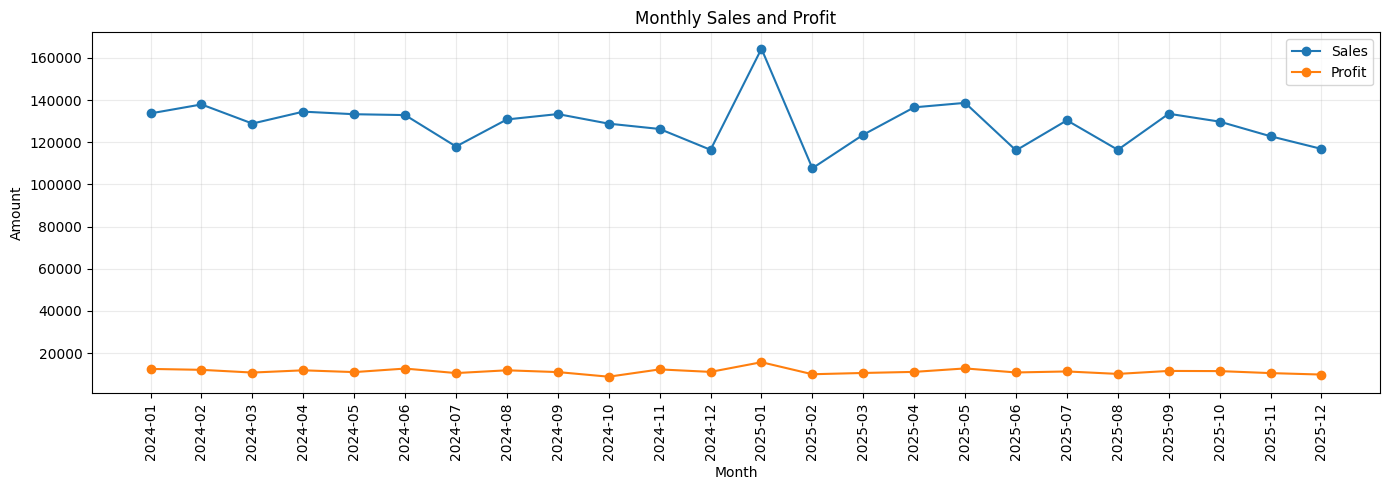

In [5]:
monthly = df.groupby('Month', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
plt.figure(figsize=(14,5))
plt.plot(monthly['Month'], monthly['Sales'], marker='o', label='Sales')
plt.plot(monthly['Month'], monthly['Profit'], marker='o', label='Profit')
plt.xticks(rotation=90)
plt.title('Monthly Sales and Profit')
plt.xlabel('Month'); plt.ylabel('Amount'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout()
plt.show()


## 6. Category performance

,Category,Sales,Profit,Quantity
2,Technology,1546032.83,172760.58,10255
0,Furniture,1124520.40,62477.85,11403
1,Office Supplies,420511.77,36060.33,14366


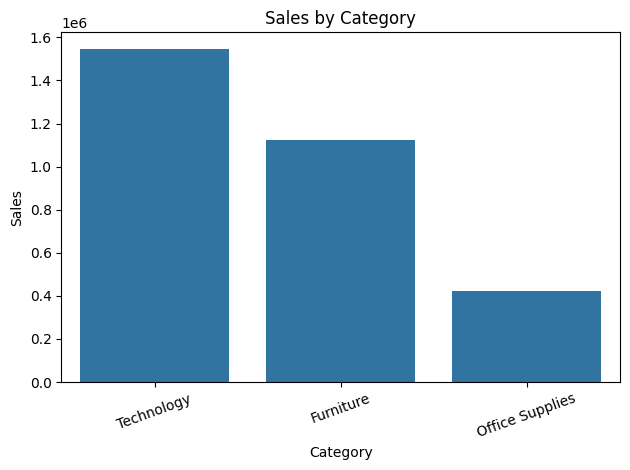

In [6]:
category_perf = df.groupby('Category', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Quantity=('Quantity','sum')).sort_values('Sales', ascending=False)
display(category_perf)
sns.barplot(data=category_perf, x='Category', y='Sales')
plt.title('Sales by Category'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()


## 7. Regional performance

,Region,Sales,Profit,Orders
3,West,907389.04,78927.02,2362
1,East,768220.52,66618.44,1950
2,South,730768.67,63174.54,1868
0,Central,684686.77,62578.76,1820


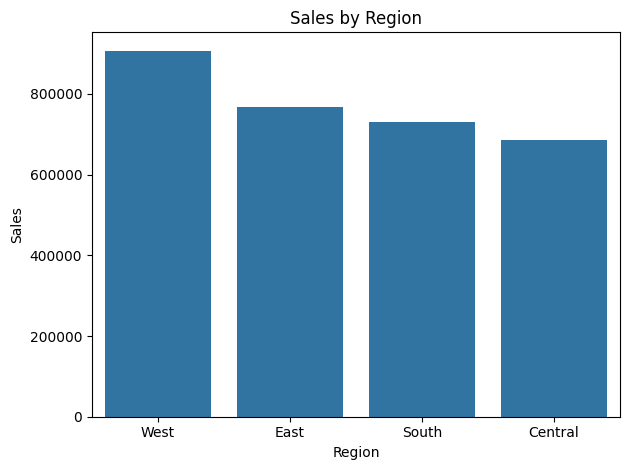

In [7]:
region_perf = df.groupby('Region', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','nunique')).sort_values('Sales', ascending=False)
display(region_perf)
sns.barplot(data=region_perf, x='Region', y='Sales')
plt.title('Sales by Region'); plt.tight_layout(); plt.show()


## 8. Top 10 products

,Product Name,Sales,Profit,Quantity
30,Production Copier,211623.86,25323.21,1375
4,Compact Copier,196114.76,21668.75,1384
23,Nova X Smartphone,148438.88,16134.96,912
2,Apex Business Phone,145286.65,16180.84,950
16,Laser Printer,131660.83,15218.93,836
27,Orbit Wireless Phone,123482.33,13381.96,794
10,Desktop Workstation,120915.22,11423.25,791
26,Office Scanner,116221.04,13559.85,788
24,Oak Bookcase,105323.44,5257.80,1058
22,Noise-Cancelling Headset,103924.49,11409.67,663


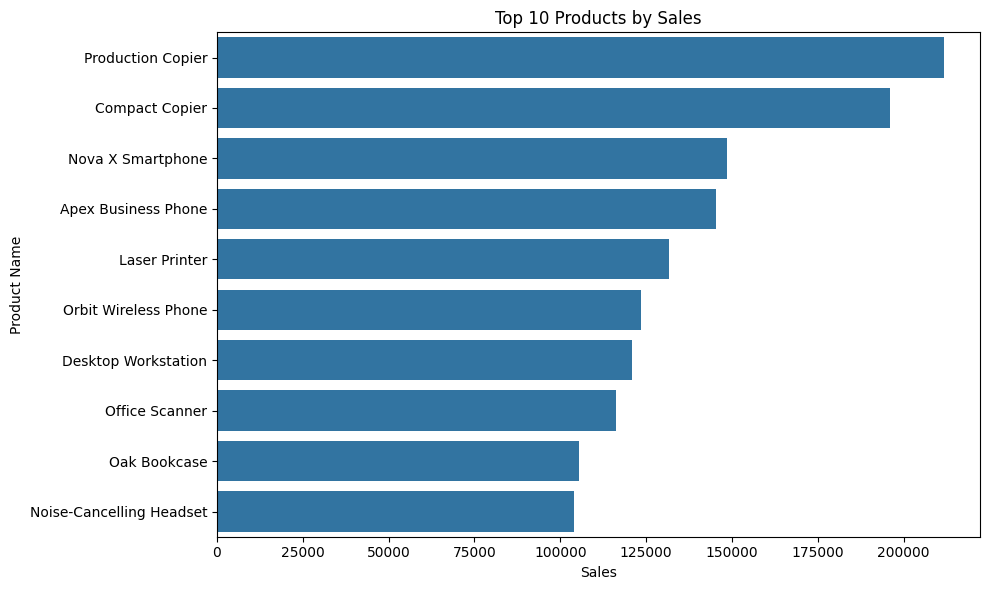

In [8]:
top_products = df.groupby('Product Name', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Quantity=('Quantity','sum')).sort_values('Sales', ascending=False).head(10)
display(top_products)
plt.figure(figsize=(10,6))
sns.barplot(data=top_products, y='Product Name', x='Sales')
plt.title('Top 10 Products by Sales'); plt.tight_layout(); plt.show()


## 9. Discount and profitability

,Discount,Sales,Profit,Orders
0,0.00,997784.51,160727.63,2269
1,0.05,392909.16,50297.23,968
2,0.10,596789.52,55708.76,1443
3,0.15,399467.40,22041.13,1104
4,0.20,375781.16,7626.81,1112
5,0.30,232101.28,-12358.34,719
6,0.40,96231.97,-12744.46,385


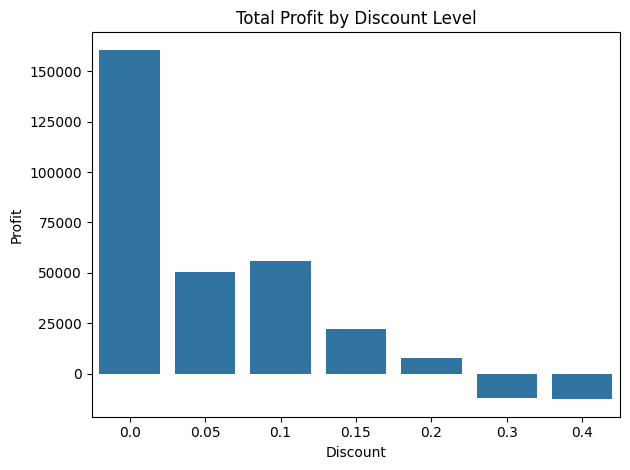

In [9]:
discount_perf = df.groupby('Discount', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','nunique')).sort_values('Discount')
display(discount_perf)
sns.barplot(data=discount_perf, x='Discount', y='Profit')
plt.title('Total Profit by Discount Level'); plt.tight_layout(); plt.show()


## 10. Export cleaned dataset and summary tables

In [10]:
df.to_csv('cleaned_sales_data.csv', index=False)
category_perf.to_csv('category_performance.csv', index=False)
region_perf.to_csv('regional_performance.csv', index=False)
top_products.to_csv('top_10_products.csv', index=False)
files.download('cleaned_sales_data.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Business interpretation
Use the KPI and charts above to identify the leading category, region and products. Compare profit as well as sales. Investigate discount levels where total profit is weak or negative. All findings must be described as findings from a synthetic demonstration dataset.